# Comparación y selección de modelos ANN

## Sistema de predicción de riesgo crediticio

Este notebook resume y compara las configuraciones evaluadas en los modelos
de redes neuronales artificiales del proyecto.

La comparación se realiza utilizando los resultados registrados en:

- `03_ANN_Modelo1.ipynb`
- `04_ANN_Modelo_2.ipynb`

No se vuelve a entrenar ningún modelo. Se utilizan las curvas y métricas
obtenidas durante los entrenamientos originales.

In [1]:
# Librerías para organizar y visualizar la comparación

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 1. Comparación de configuraciones del modelo binario

Para el modelo de clasificación binaria se probaron dos configuraciones.

### Configuración 1: EarlyStopping sin Dropout

Arquitectura:

- Capa oculta de 61 neuronas con activación ReLU.
- Capa oculta de 20 neuronas con activación ReLU.
- Capa de salida de una neurona con activación Sigmoid.
- Función de pérdida `binary_crossentropy`.
- Optimizador Adam.
- EarlyStopping con paciencia de 5 épocas.
- Sin capas Dropout.

El entrenamiento se detuvo en la época 16. La menor pérdida de validación
registrada fue 0.5026 en la época 11.

### Configuración 2: EarlyStopping con Dropout

Arquitectura:

- Capa oculta de 61 neuronas con activación ReLU.
- Dropout de 0.5.
- Capa oculta de aproximadamente 31 neuronas con activación ReLU.
- Dropout de 0.5.
- Capa de salida de una neurona con activación Sigmoid.
- Función de pérdida `binary_crossentropy`.
- Optimizador Adam.
- EarlyStopping con paciencia de 5 épocas.

El entrenamiento se detuvo en la época 28. La menor pérdida de validación
registrada fue 0.4872 en la época 23.

In [2]:
comparacion_binario = pd.DataFrame({
    "Configuración": [
        "EarlyStopping sin Dropout",
        "EarlyStopping con Dropout"
    ],
    "Capas ocultas": [
        "61 - 20",
        "61 - 31"
    ],
    "Dropout": [
        "No utiliza",
        "0.5 después de cada capa oculta"
    ],
    "Épocas ejecutadas": [
        16,
        28
    ],
    "Mejor época según val_loss": [
        11,
        23
    ],
    "Mejor val_loss": [
        0.5026,
        0.4872
    ]
})

comparacion_binario

,Configuración,Capas ocultas,Dropout,Épocas ejecutadas,Mejor época según val_loss,Mejor val_loss
0,EarlyStopping sin Dropout,61 - 20,No utiliza,16,11,0.5026
1,EarlyStopping con Dropout,61 - 31,0.5 después de cada capa oculta,28,23,0.4872


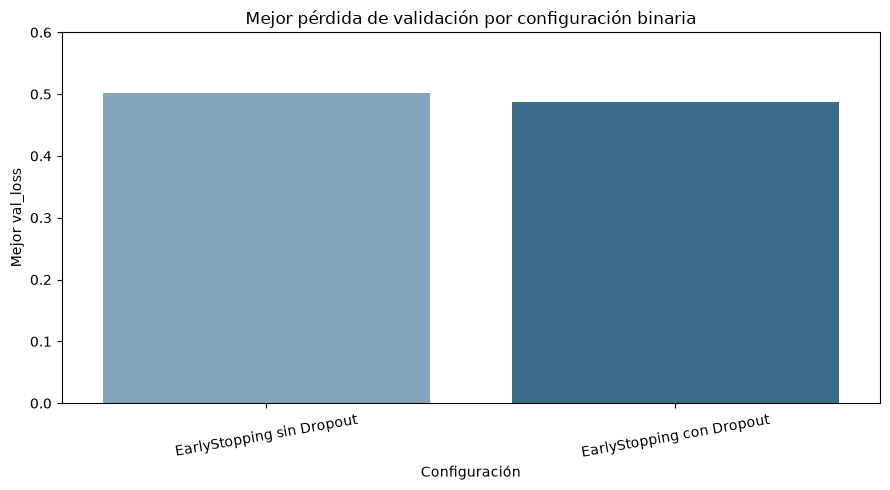

In [3]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparacion_binario,
    x="Configuración",
    y="Mejor val_loss",
    hue="Configuración",
    palette=["#7AA6C2", "#2E6F95"],
    legend=False
)

plt.title("Mejor pérdida de validación por configuración binaria")
plt.xlabel("Configuración")
plt.ylabel("Mejor val_loss")
plt.ylim(0, 0.60)
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

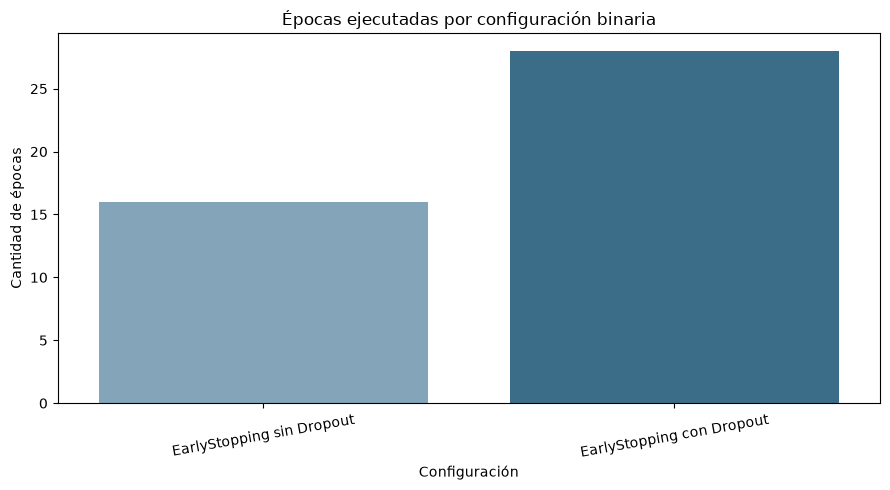

In [4]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=comparacion_binario,
    x="Configuración",
    y="Épocas ejecutadas",
    hue="Configuración",
    palette=["#7AA6C2", "#2E6F95"],
    legend=False
)

plt.title("Épocas ejecutadas por configuración binaria")
plt.xlabel("Configuración")
plt.ylabel("Cantidad de épocas")
plt.xticks(rotation=10)
plt.tight_layout()
plt.show()

### Análisis de las configuraciones binarias

La configuración sin Dropout aprendió más rápidamente y el entrenamiento
finalizó en la época 16. Su menor pérdida de validación fue 0.5026.

La configuración con Dropout necesitó 28 épocas, debido a que durante cada
época se desactivó temporalmente el 50 % de las neuronas de las capas
ocultas. Sin embargo, obtuvo una pérdida de validación menor, de 0.4872.

La menor pérdida de validación indica que la configuración con Dropout tuvo
un mejor comportamiento sobre los datos de validación durante el
entrenamiento.

Por esta razón, la configuración con Dropout se utilizó como modelo binario
final y fue la configuración evaluada sobre el conjunto de prueba.

Una limitación de la comparación es que el notebook no conservó una
evaluación independiente del modelo sin Dropout sobre el conjunto de prueba.
Por ello, la comparación directa entre ambos se basa en las curvas y en la
pérdida de validación registrada durante el entrenamiento.

## 2. Evaluación del modelo binario seleccionado

La evaluación final registrada en el notebook corresponde a la última
configuración entrenada, es decir, el modelo que utiliza EarlyStopping y
dos capas Dropout de 0.5.

La clase 0 representa un crédito Bueno y la clase 1 representa un crédito Malo.

In [5]:
metricas_binario = pd.DataFrame({
    "Clase": [
        "Bueno",
        "Malo"
    ],
    "Precision": [
        0.78,
        0.69
    ],
    "Recall": [
        0.92,
        0.40
    ],
    "F1-score": [
        0.85,
        0.51
    ],
    "Soporte": [
        140,
        60
    ]
})

metricas_binario

,Clase,Precision,Recall,F1-score,Soporte
0,Bueno,0.78,0.92,0.85,140
1,Malo,0.69,0.40,0.51,60


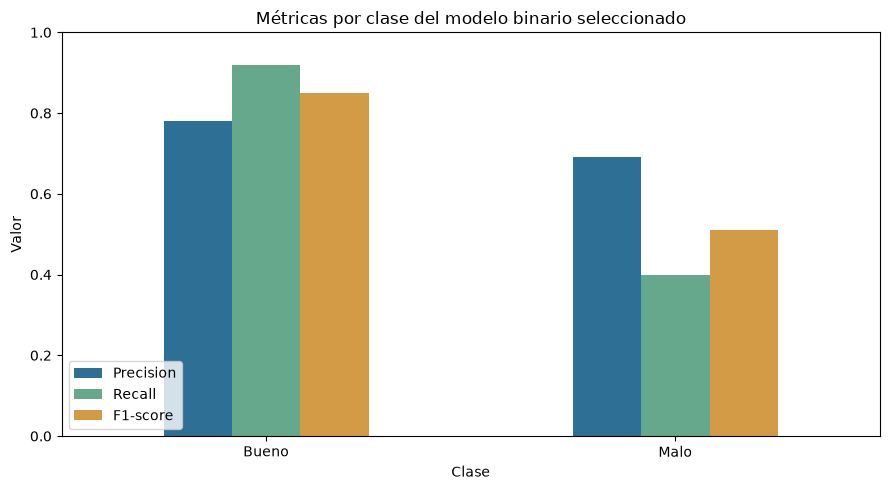

In [6]:
metricas_binario.set_index("Clase")[
    ["Precision", "Recall", "F1-score"]
].plot(
    kind="bar",
    figsize=(9, 5),
    color=["#2E6F95", "#65A88C", "#D39B45"]
)

plt.title("Métricas por clase del modelo binario seleccionado")
plt.xlabel("Clase")
plt.ylabel("Valor")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

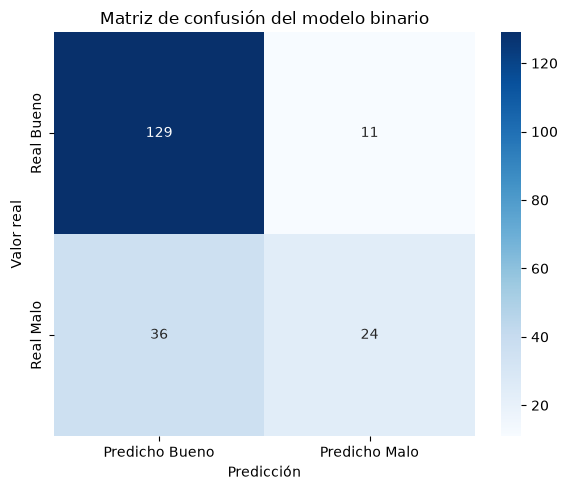

In [9]:
matriz_binario = [
    [129, 11],
    [36, 24]
]

plt.figure(figsize=(6, 5))

sns.heatmap(
    matriz_binario,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Predicho Bueno", "Predicho Malo"],
    yticklabels=["Real Bueno", "Real Malo"]
)

plt.title("Matriz de confusión del modelo binario")
plt.xlabel("Predicción")
plt.ylabel("Valor real")
plt.tight_layout()
plt.show()

### Interpretación del modelo binario

El modelo obtuvo una exactitud de 0.77.

El mejor desempeño se presentó en la clase Bueno:

- Identificó correctamente 129 de los 140 créditos buenos.
- Su recall para la clase Bueno fue 0.92.

La principal limitación se presentó en la clase Malo:

- Identificó correctamente 24 de los 60 créditos malos.
- Clasificó 36 créditos malos como buenos.
- Su recall para la clase Malo fue 0.40.

Esto demuestra que la exactitud no debe interpretarse de forma aislada. La
distribución original contiene 70 % de créditos buenos y 30 % de créditos
malos, por lo que la identificación de la clase minoritaria representa el
principal aspecto que debe mejorarse.

## 3. Evaluación del modelo multiclase híbrido

El modelo multiclase utiliza una arquitectura distinta porque clasifica cuatro
niveles de riesgo:

- Bajo.
- Medio.
- Alto.
- Crítico.

Su entrada está formada por:

- 61 variables preprocesadas.
- El puntaje de exposición normalizado.
- La probabilidad generada por el modelo binario.

En total, el modelo recibe 63 entradas.

La arquitectura utiliza:

- Tres capas ocultas de 126, 63 y 31 neuronas.
- Activación ReLU.
- Regularización L2.
- Tres capas Dropout de 0.3.
- Pesos de clase balanceados.
- EarlyStopping.
- ReduceLROnPlateau.
- Cuatro neuronas de salida con activación Softmax.

In [10]:
metricas_multiclase = pd.DataFrame({
    "Clase": [
        "Bajo",
        "Medio",
        "Alto",
        "Crítico"
    ],
    "Precision": [
        0.85,
        0.56,
        0.57,
        0.61
    ],
    "Recall": [
        0.88,
        0.46,
        0.50,
        0.77
    ],
    "F1-score": [
        0.86,
        0.51,
        0.53,
        0.68
    ],
    "Soporte": [
        101,
        39,
        34,
        26
    ]
})

metricas_multiclase

,Clase,Precision,Recall,F1-score,Soporte
0,Bajo,0.85,0.88,0.86,101
1,Medio,0.56,0.46,0.51,39
2,Alto,0.57,0.50,0.53,34
3,Crítico,0.61,0.77,0.68,26


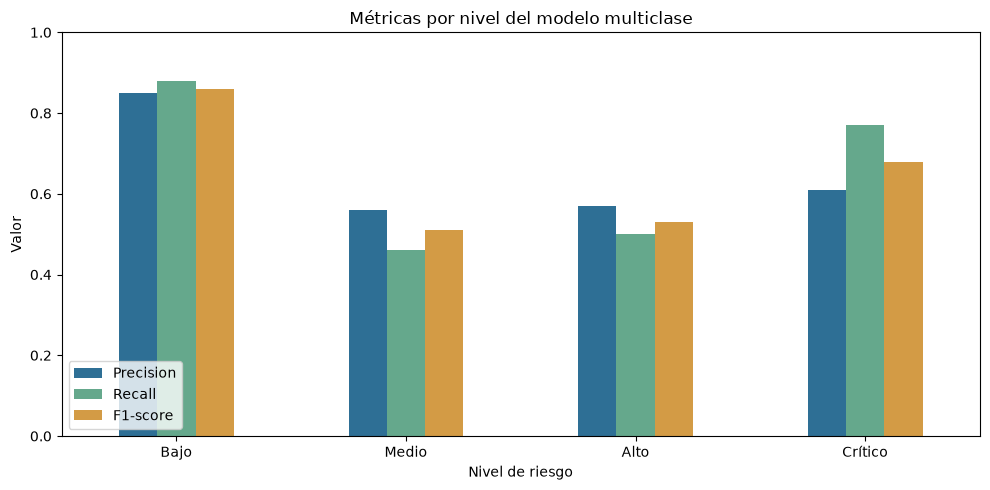

In [12]:
metricas_multiclase.set_index("Clase")[
    ["Precision", "Recall", "F1-score"]
].plot(
    kind="bar",
    figsize=(10, 5),
    color=["#2E6F95", "#65A88C", "#D39B45"]
)

plt.title("Métricas por nivel del modelo multiclase")
plt.xlabel("Nivel de riesgo")
plt.ylabel("Valor")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

### Interpretación del modelo multiclase

El modelo multiclase obtuvo:

- Accuracy de 0.72.
- F1 macro de 0.65.
- ROC-AUC macro de 0.8756.

El nivel Bajo obtuvo el mejor rendimiento, con un F1-score de 0.86.

El nivel Crítico obtuvo un recall de 0.77, lo que indica que el modelo logró
identificar una proporción importante de los casos críticos.

Las clases Medio y Alto fueron las más difíciles de separar:

- Medio obtuvo un F1-score de 0.51.
- Alto obtuvo un F1-score de 0.53.

El uso de pesos de clase permitió prestar mayor atención a las categorías
con menor cantidad de registros.

## 4. Comparación funcional de los modelos finales

El modelo binario y el modelo multiclase no se comparan para decidir cuál es
mejor, porque resuelven objetivos diferentes.

El modelo binario responde:

> ¿El crédito se clasifica como Bueno o Malo?

El modelo multiclase responde:

> ¿El nivel de riesgo se clasifica como Bajo, Medio, Alto o Crítico?

La siguiente tabla resume sus diferencias.

In [13]:
resumen_modelos = pd.DataFrame({
    "Característica": [
        "Objetivo",
        "Clases",
        "Entradas",
        "Activación de salida",
        "Función de pérdida",
        "Dropout",
        "Accuracy de prueba",
        "F1 macro",
        "ROC-AUC macro"
    ],
    "Modelo binario": [
        "Clasificar crédito Bueno o Malo",
        "2",
        "61",
        "Sigmoid",
        "Binary crossentropy",
        "0.5 en dos capas",
        0.77,
        0.68,
        "No calculado"
    ],
    "Modelo multiclase": [
        "Clasificar nivel de riesgo",
        "4",
        "63",
        "Softmax",
        "Sparse categorical crossentropy",
        "0.3 en tres capas",
        0.72,
        0.65,
        0.8756
    ]
})

resumen_modelos

,Característica,Modelo binario,Modelo multiclase
0,Objetivo,Clasificar crédito Bueno o Malo,Clasificar nivel de riesgo
1,Clases,2,4
2,Entradas,61,63
3,Activación de salida,Sigmoid,Softmax
4,Función de pérdida,Binary crossentropy,Sparse categorical crossentropy
5,Dropout,0.5 en dos capas,0.3 en tres capas
6,Accuracy de prueba,0.77,0.72
7,F1 macro,0.68,0.65
8,ROC-AUC macro,No calculado,0.8756


## 5. Conclusiones de la comparación

1. En el modelo binario se probaron dos configuraciones:
   EarlyStopping sin Dropout y EarlyStopping con Dropout.

2. La configuración con Dropout obtuvo una menor pérdida de validación:
   0.4872 frente a 0.5026 de la configuración sin Dropout.

3. La configuración con Dropout necesitó más épocas, pero mostró un mejor
   comportamiento sobre los datos de validación.

4. El modelo binario final obtuvo una accuracy de 0.77. Su principal
   limitación fue el recall de 0.40 para la clase Malo.

5. El modelo multiclase híbrido obtuvo una accuracy de 0.72, F1 macro de
   0.65 y ROC-AUC macro de 0.8756.

6. El nivel Bajo presentó el mejor desempeño multiclase. Las clases Medio y
   Alto fueron las más difíciles de diferenciar.

7. El modelo multiclase se beneficia del uso de regularización L2, Dropout,
   pesos de clase, EarlyStopping y reducción automática del learning rate.

8. Los dos modelos son complementarios: el binario produce una primera
   clasificación Bueno o Malo y su probabilidad se utiliza como entrada del
   modelo multiclase.

### Limitación

El proyecto no incluye una segunda configuración multiclase evaluada de forma
independiente. Por esta razón, la comparación multiclase se centra en el
rendimiento por clase, las curvas de entrenamiento y las métricas globales
del modelo híbrido implementado.